The way to determine if the parameters for PSF resampler are correct is to check how the PSD before and after resampling compare.

This notebook explores the computation of spectra for both input and resampled.

I am selecting a square area in healpix (rotated by 45°).
A parent cell barely fits the swath, not ideal.
I start from a center pixel, that I enlarge using healpix_geo.nested.kth_neighbourhood.
If I put those cell ids in ring, they can be sorted (left to right, top ring to bottom ring) and then reordered to be wrapped in a 2D array.

In [1]:
%matplotlib inline

import logging

import cartopy.crs as ccrs
import healpix_geo.ring
import healpix_geo.nested
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from scipy.signal.windows import tukey

from cdshealpix import to_ring, from_ring
from healpix_analyse.powerspectra import powerspectra
from healpix_analyse.powerspectra_lonlat import powerspectra_lonlat
from healpix_resample import PSFResampler, NearestResampler, subset_for_parent_cell
from matplotlib.collections import PolyCollection

from swot_healpix.data import SWOT

log = logging.getLogger(__name__)
logging.basicConfig(level=logging.INFO)

In [2]:
# 15: 198m
# 10: 6.3km
level = 15

track = SWOT(cycle=546, track=19, version="PGC0")

# Load data

In [16]:
swot_file = track.get_file()
swath = xr.open_dataset(swot_file, group="left", chunks=-1)

# swath = swath.isel(num_lines=slice(18_400, 19_100))
swath = swath.isel(num_lines=slice(60_000, 61_000))

# Left swath, we flip to have ascending longitude
swath = swath.isel(num_pixels=slice(None, None, -1))
if track.pass_type == "descending":
    swath = swath.isel(num_lines=slice(None, None, -1))

swath.longitude.load()
swath.latitude.load()
swath.ssh_karin_2.load()

swath = swath.dropna("num_lines", how="all", subset=["longitude"])
swath = swath.dropna("num_pixels", how="all", subset=["longitude"])

# swath = swath.isel(num_lines=slice(0, swath.num_pixels.size))

swath["ssh_karin_2"] -= swath.ssh_karin_2.mean()

swath

<xarray.Dataset> Size: 23MB
Dimensions:                                (num_lines: 1000, num_pixels: 233)
Coordinates:
    latitude                               (num_lines, num_pixels) float64 2MB ...
    longitude                              (num_lines, num_pixels) float64 2MB ...
Dimensions without coordinates: num_lines, num_pixels
Data variables: (12/16)
    time                                   (num_lines) datetime64[ns] 8kB dask.array<chunksize=(1000,), meta=np.ndarray>
    time_tai                               (num_lines) datetime64[ns] 8kB dask.array<chunksize=(1000,), meta=np.ndarray>
    latitude_uncert                        (num_lines, num_pixels) float64 2MB dask.array<chunksize=(1000, 233), meta=np.ndarray>
    longitude_uncert                       (num_lines, num_pixels) float64 2MB dask.array<chunksize=(1000, 233), meta=np.ndarray>
    polarization_karin                     (num_lines) object 8kB dask.array<chunksize=(1000,), meta=np.ndarray>
    ssh_karin_2                            (num_lines, num_pixels) float64 2MB ...
    ...                                     ...
    sig0_karin_uncert                      (num_lines, num_pixels) float32 932kB dask.array<chunksize=(1000, 233), meta=np.ndarray>
    total_coherence                        (num_lines, num_pixels) float64 2MB dask.array<chunksize=(1000, 233), meta=np.ndarray>
    mean_sea_surface_cnescls               (num_lines, num_pixels) float64 2MB dask.array<chunksize=(1000, 233), meta=np.ndarray>
    miti_power_250m                        (num_lines, num_pixels) float32 932kB dask.array<chunksize=(1000, 233), meta=np.ndarray>
    miti_power_var_250m                    (num_lines, num_pixels) float32 932kB dask.array<chunksize=(1000, 233), meta=np.ndarray>
    ancillary_surface_classification_flag  (num_lines, num_pixels) float32 932kB dask.array<chunksize=(1000, 233), meta=np.ndarray>
Attributes:
    description:  Unsmoothed SSH measurement data and related information for...

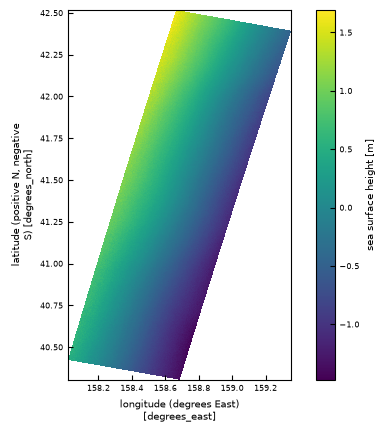

In [17]:
swath.ssh_karin_2.plot.pcolormesh(x="longitude", y="latitude", center=False)
plt.gca().set_aspect("equal")

# Select chunk

Find a large chunk in healpix space and find indices to reshape it in 2D

In [18]:
n_ring = 100
n_side = 2 * n_ring + 1

center_i_line = swath.num_lines.size // 2
center_i_pixel = swath.num_pixels.size // 2
center_pixel = swath.isel(num_pixels=center_i_pixel, num_lines=center_i_line)
center_id = healpix_geo.nested.lonlat_to_healpix(
    float(center_pixel.longitude),
    float(center_pixel.latitude),
    depth=level,
    ellipsoid="WGS84",
)


indices = []
i_cell_start = 0
n_cell_ring = 1
for i_ring in range(n_side):
    i_cells_ring = np.arange(i_cell_start, i_cell_start + n_cell_ring)

    ix = np.arange(0, n_cell_ring)
    iy = np.arange(n_cell_ring - 1, -1, -1)
    i = iy * n_side + ix
    indices += list(i)

    i_cell_start += n_cell_ring
    n_cell_ring += 1

n_cell_ring -= 2

for i_ring in range(n_side - 1):
    i_cells_ring = np.arange(i_cell_start, i_cell_start + n_cell_ring)

    ix = np.arange(0, n_cell_ring) + i_ring + 1
    iy = np.arange(n_cell_ring - 1, -1, -1) + i_ring + 1
    i = iy * n_side + ix
    indices += list(i)

    i_cell_start += n_cell_ring
    n_cell_ring -= 1

indices = np.asarray(indices)

chunk_ids = healpix_geo.nested.kth_neighbourhood(center_id, depth=level, ring=n_ring)[0]

# Resample

In [19]:
lon = swath.longitude.values.ravel()
lat = swath.latitude.values.ravel()
ssh = swath.ssh_karin_2.values.ravel()

resampler = PSFResampler(
    lon_deg=lon,
    lat_deg=lat,
    level=level,
    out_cell_ids=chunk_ids,
    verbose=True,
)
resampled = resampler.resample(ssh, lam=0.5)

[PSFResampler] area not provided and no shared-latitude-ring structure detected: falling back to a uniform weight of 1.0 per sample.
Itt 0 : 0.01271
Itt 4 : 1.504e-07
Itt 8 : 4.414e-12
Itt 12 : 1.096e-16
Final Itt 13 : 8.037e-18


In [20]:
cell_ids = to_ring(resampled.cell_ids, depth=level)
i_sort = np.argsort(cell_ids)
cell_ids = np.take(cell_ids, i_sort)
ssh_hp = np.take(resampled.cell_data, i_sort)

ssh_hp_2d = np.zeros((n_side, n_side))
np.put(ssh_hp_2d, indices, ssh_hp)
np.put(cell_ids, indices, cell_ids)

chunk_lon, chunk_lat = healpix_geo.ring.healpix_to_lonlat(
    cell_ids, depth=level, ellipsoid="WGS84"
)
chunk_lon_2d = np.reshape(chunk_lon, (n_side, n_side))
chunk_lat_2d = np.reshape(chunk_lat, (n_side, n_side))

# Find (half) span for swath
nx = int(n_side * 198 / 235)
ny = int(n_side * 198 / 250)
iy0 = center_i_line - ny // 2
iy1 = center_i_line + ny // 2
ix0 = center_i_pixel - nx // 2
ix1 = center_i_pixel + ny // 2

if iy0 < 0 or iy1 > swath.num_lines.size or ix0 < 0 or ix1 > swath.num_pixels.size:
    print("Chunk is too big to fit in current swath :(")

span = swath.isel(
    num_lines=slice(max(0, center_i_line - ny // 2), center_i_line + ny // 2),
    num_pixels=slice(max(0, center_i_pixel - nx // 2), center_i_pixel + nx // 2),
)

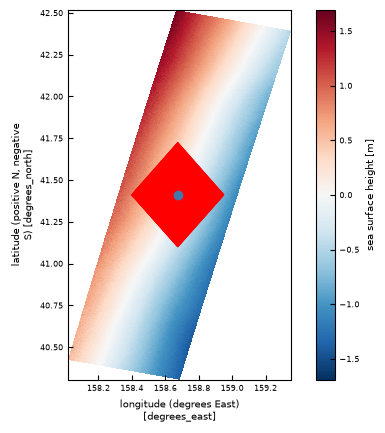

In [21]:
fig, ax = plt.subplots()

swath.ssh_karin_2.plot.pcolormesh(x="longitude", y="latitude")

vertices = np.stack(
    healpix_geo.ring.vertices(cell_ids, depth=level, ellipsoid="WGS84"),
    axis=-1,
)
ax.add_artist(PolyCollection(vertices, ec="r", lw=0.7, fc="none"))
ax.scatter(center_pixel.longitude, center_pixel.latitude)

if len(cell_ids) < 100:
    for i_cell, cell_id in enumerate(cell_ids):
        xy = healpix_geo.ring.healpix_to_lonlat(cell_id, depth=level, ellipsoid="WGS84")
        xy = [x[0] for x in xy]
        ax.annotate(
            i_cell,
            xy=xy,
            ha="center",
            va="center",
            color="r",
        )

ax.set_aspect("equal")

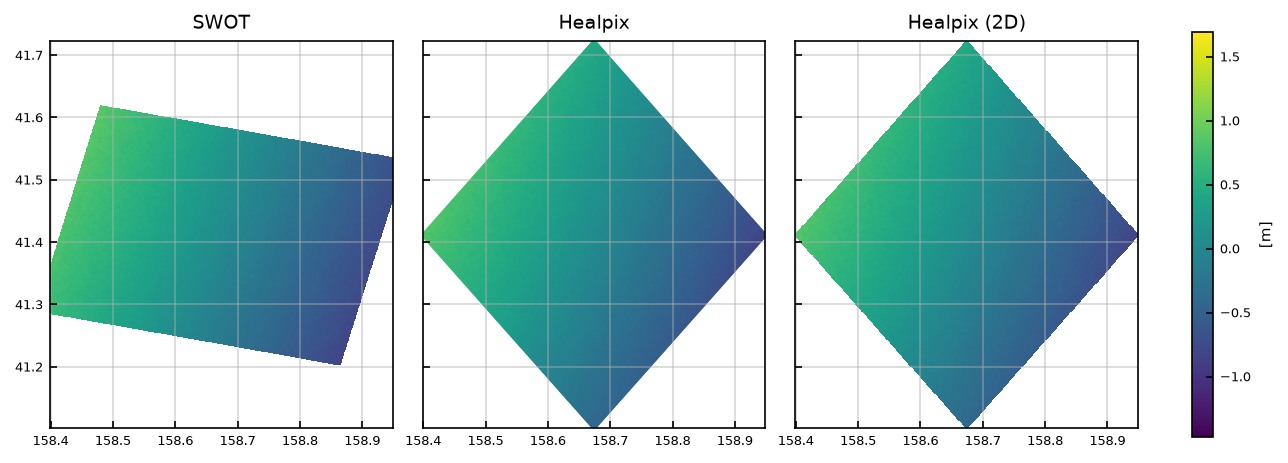

In [22]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(8.5, 3),
    layout="constrained",
    sharex=True,
    sharey=True,
    dpi=150,
)
ax1, ax2, ax3 = axes

vmin = float(swath.ssh_karin_2.min())
vmax = float(swath.ssh_karin_2.max())

im = span.ssh_karin_2.plot.pcolormesh(
    x="longitude",
    y="latitude",
    vmin=vmin,
    vmax=vmax,
    ax=ax1,
    add_labels=False,
    add_colorbar=False,
)
ax1.set_title("SWOT")

vertices = np.stack(
    healpix_geo.nested.vertices(resampled.cell_ids, depth=level, ellipsoid="WGS84"),
    axis=-1,
)
colorizer = plt.Colorizer(norm=plt.Normalize(vmin=vmin, vmax=vmax))
colors = colorizer.to_rgba(resampled.cell_data)
polys = PolyCollection(vertices, ec=colors, fc=colors)
ax2.add_collection(polys)
ax2.set_title("Healpix")

ax3.pcolormesh(chunk_lon_2d, chunk_lat_2d, ssh_hp_2d, vmin=vmin, vmax=vmax)
ax3.set_title("Healpix (2D)")

ax1.set_xlim(np.min(chunk_lon), np.max(chunk_lon))
ax1.set_ylim(np.min(chunk_lat), np.max(chunk_lat))

fig.colorbar(im, ax=axes, label="[m]")

for ax in axes:
    ax.set_aspect("equal")
    ax.grid(True)

# Spectra

In [23]:
def ps(data, data_cross=None, plot_2D_fft=False, dx=1.0, dy=1.0):
    """Custom power spectra computation.

    Lifted from healpix_analyse.ps. Added dx/dy
    """

    if data_cross is None:
        P2D = np.abs(np.fft.fftshift(np.fft.fft2(data))) ** 2
    else:
        P2D = np.abs(np.fft.fftshift(np.fft.fft2(data) * np.conj(np.fft.fft2(data_cross))))

    if plot_2D_fft:
        import matplotlib.pyplot as plt
        plt.imshow(P2D, norm='log')
        plt.colorbar(label='Power (log scale)', orientation='horizontal')
        plt.show()

    # Spatial frequency grids (cycles per unit length; NOT radians)
    ny, nx = P2D.shape
    fx = np.fft.fftshift(np.fft.fftfreq(nx, d=dx))  # cycles per unit length (e.g., m^-1)
    fy = np.fft.fftshift(np.fft.fftfreq(ny, d=dy))  # cycles per unit length (e.g., m^-1)
    fx2d, fy2d = np.meshgrid(fx, fy, indexing="xy")
    fr = np.sqrt(fx2d**2 + fy2d**2)  # radial spatial frequency (cycles per unit length)

    # Radial binning
    nbins = min(nx, ny) // 2
    f_bins = np.linspace(0.0, fr.max(), nbins + 1)

    # Vectorized bin average of P2D over annuli
    fr_flat = fr.ravel()
    P_flat = P2D.ravel()
    bin_idx = np.digitize(fr_flat, f_bins) - 1  # -> [0, nbins-1]
    valid = (bin_idx >= 0) & (bin_idx < nbins)

    # Sum and count per bin, then mean
    sum_per_bin = np.bincount(bin_idx[valid], weights=P_flat[valid], minlength=nbins)
    cnt_per_bin = np.bincount(bin_idx[valid], minlength=nbins)
    with np.errstate(invalid="ignore", divide="ignore"):
        Pk = sum_per_bin / cnt_per_bin
    Pk[cnt_per_bin == 0] = np.nan  # empty bins

    # Bin centers
    f_centers = 0.5 * (f_bins[1:] + f_bins[:-1])

    return f_centers, Pk / (nx*ny)

In [24]:
# Input
ssh = span.ssh_karin_2.values
    
alpha = 0.2

ny, nx = ssh.shape
win_x = tukey(nx, alpha=alpha)
win_y = tukey(ny, alpha=alpha)
apodizing_window = win_y[:, None] * win_x[None, :]

# 1d
freqs, spectrum = ps(apodizing_window * ssh, dx=235, dy=250)

# 2d
fft_2d = np.fft.fftshift(np.abs(np.fft.fft2(apodizing_window * ssh)))
# cycles.km^-1
fx = np.fft.fftshift(np.fft.fftfreq(nx, d=235)) * 1000
fy = np.fft.fftshift(np.fft.fftfreq(ny, d=250)) * 1000

In [25]:
# Resampled
alpha = 0.2

ny, nx = ssh_hp_2d.shape
win_x = tukey(nx, alpha=alpha)
win_y = tukey(ny, alpha=alpha)
apodizing_window = win_y[:, None] * win_x[None, :]

# 1d
freqs_hp, spectrum_hp = ps(apodizing_window * ssh_hp_2d, dx=190, dy=190)
# 2d
fft_2d_hp = np.fft.fftshift(np.abs(np.fft.fft2(apodizing_window * ssh_hp_2d)))
# cycles.km^-1
fx_hp = np.fft.fftshift(np.fft.fftfreq(nx, d=198)) * 1000
fy_hp = np.fft.fftshift(np.fft.fftfreq(ny, d=198)) * 1000

Text(0, 0.5, '[cycle/km]')

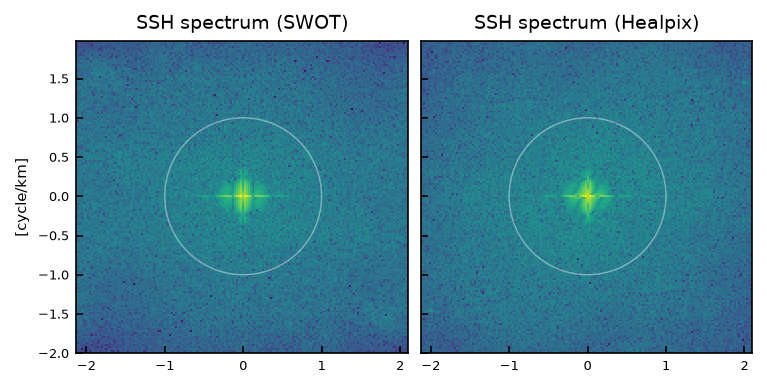

In [26]:
fig, axes = plt.subplots(
    1, 2, layout="constrained", figsize=(5, 2.5), dpi=150, sharex=True, sharey=True
)
ax1, ax2 = axes

ax1.pcolormesh(fx, fy, fft_2d, norm="log")
ax1.set_title("SSH spectrum (SWOT)")
ax2.pcolormesh(fx_hp, fy_hp, fft_2d_hp, norm="log")
ax2.set_title("SSH spectrum (Healpix)")

ax1.set_xlim(fx[0], fx[-1])
ax1.set_ylim(fy[0], fy[-1])

for ax in axes:
    ax.set_aspect("equal")
    ax.grid(False)

    for dist in [1000]:
        ax.add_artist(plt.Circle(
            (0, 0),
            radius=1/(dist/1000),
            lw=0.7,
            ec="w",
            alpha=0.4,
            fc="none",
        ))
        

ax1.set_ylabel("[cycle/km]")

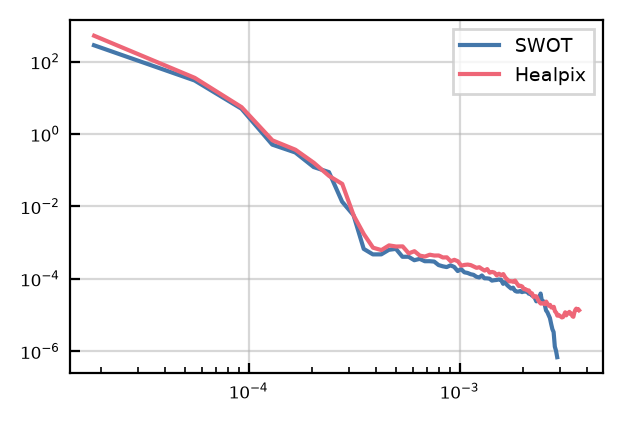

In [27]:
fig, ax = plt.subplots(layout="constrained", figsize=(3, 2), dpi=200)
ax.plot(freqs, spectrum, label="SWOT")
ax.plot(freqs_hp, spectrum_hp, label="Healpix")
ax.legend()
ax.set_xscale("log")
ax.set_yscale("log")